In [2]:
import optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense, LSTM, GRU, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from keras.optimizers import Adam, SGD, RMSprop, Adagrad
from sklearn.preprocessing import MinMaxScaler

In [3]:
data=pd.read_csv(r'bitcoin.csv')
data

,Currency,Date,Closing Price (USD),24h Open (USD),24h High (USD),24h Low (USD)
0,BTC,2013-10-01,123.654990,124.304660,124.751660,122.563490
1,BTC,2013-10-02,125.455000,123.654990,125.758500,123.633830
2,BTC,2013-10-03,108.584830,125.455000,125.665660,83.328330
3,BTC,2013-10-04,118.674660,108.584830,118.675000,107.058160
4,BTC,2013-10-05,121.338660,118.674660,121.936330,118.005660
...,...,...,...,...,...,...
2782,BTC,2021-05-14,49764.132082,49596.778891,51448.798576,46294.720180
2783,BTC,2021-05-15,50032.693137,49717.354353,51578.312545,48944.346536
2784,BTC,2021-05-16,47885.625255,49926.035067,50690.802950,47005.102292
2785,BTC,2021-05-17,45604.615754,46805.537852,49670.414174,43868.638969


In [4]:
data.dtypes

Currency                object
Date                    object
Closing Price (USD)    float64
24h Open (USD)         float64
24h High (USD)         float64
24h Low (USD)          float64
dtype: object

In [5]:
data['Date'] = pd.to_datetime(data['Date'])

In [6]:
data.dtypes

Currency                       object
Date                   datetime64[ns]
Closing Price (USD)           float64
24h Open (USD)                float64
24h High (USD)                float64
24h Low (USD)                 float64
dtype: object

In [7]:
train_data = data[data['Date'].dt.year < 2021] 
test_data = data[data['Date'].dt.year == 2021]

In [8]:
# Train data preparation
variables = ['24h Open (USD)', '24h High (USD)', '24h Low (USD)', 'Closing Price (USD)']

train_data_set = train_data[variables].values
test_data_set = test_data[variables].values  

sc = MinMaxScaler(feature_range=(0, 1))
train_data_set_scaled = sc.fit_transform(train_data_set)

X_train = []
y_train = []
for i in range(31, len(train_data_set)):
    X_train.append(train_data_set_scaled[i-31:i, :])
    y_train.append(train_data_set_scaled[i, 0])
X_train, y_train = np.array(X_train), np.array(y_train)

# Test data preparation
dataset_total = pd.concat((train_data[variables], test_data[variables]), axis=0)
inputs = dataset_total[len(dataset_total) - len(test_data) - 31:].values
inputs = sc.transform(inputs)

X_test = []
for i in range(31, len(inputs)):
    X_test.append(inputs[i-31:i, :])
X_test = np.array(X_test)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")


X_train shape: (2618, 31, 4)
y_train shape: (2618,)
X_test shape: (138, 31, 4)


In [10]:
def create_model(trial):
    model = Sequential()

    rnn_type = trial.suggest_categorical('rnn_type', ['LSTM', 'GRU']) 
    
    n_layers = trial.suggest_int('n_layers', 1, 8) 
    
    for i in range(n_layers): 
        if i < n_layers - 1:
            return_sequences = True
        else:
            return_sequences = False
        
        units = trial.suggest_int(f'units_{i}', 20, 100)
        dropout = trial.suggest_float(f'dropout_{i}', 0.1, 0.5)

        if rnn_type == 'LSTM':
            model.add(LSTM(units=units, return_sequences=return_sequences, 
                           input_shape=(X_train.shape[1], 4)))
        else:
            model.add(GRU(units=units, return_sequences=return_sequences, 
                          input_shape=(X_train.shape[1], 4)))
        
        model.add(Dropout(dropout))

    # Output layer
    model.add(Dense(units=1))

    # Optimizer selection
    optimizer_name = trial.suggest_categorical('optimizer', ['adam', 'sgd', 'rmsprop', 'adagrad'])
    learning_rate = trial.suggest_loguniform('learning_rate', 1e-5, 1e-2)

    if optimizer_name == 'adam':
        optimizer = Adam(learning_rate=learning_rate, clipvalue=1.0)  
    elif optimizer_name == 'sgd':
        optimizer = SGD(learning_rate=learning_rate, clipvalue=1.0)
    elif optimizer_name == 'rmsprop':
        optimizer = RMSprop(learning_rate=learning_rate, clipvalue=1.0)
    elif optimizer_name == 'adagrad':
        optimizer = Adagrad(learning_rate=learning_rate, clipvalue=1.0)

    model.compile(optimizer=optimizer, loss='mean_squared_error')

    return model

def objective(trial):
    model = create_model(trial)
    
    early_stopping = EarlyStopping(monitor='loss', patience=3, restore_best_weights=True) 
    
    model.fit(X_train, y_train, epochs=20, 
              batch_size=trial.suggest_int('batch_size', 16, 64), 
              verbose=0, callbacks=[early_stopping])
    
    loss = model.evaluate(X_train, y_train, verbose=0)
    return loss


study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=10) 

print(f"Best trial: {study.best_trial.value}")
print(f"Best hyperparameters: {study.best_trial.params}")

[I 2025-06-07 11:21:14,490] A new study created in memory with name: no-name-c53eabee-1b11-4226-81fa-fa4d23091c29
/var/folders/br/yvkmbr3121n8fd9q6wdmyqfm0000gp/T/ipykernel_11624/601725690.py:31: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  learning_rate = trial.suggest_loguniform('learning_rate', 1e-5, 1e-2)
[I 2025-06-07 11:22:27,316] Trial 0 finished with value: 0.021090548485517502 and parameters: {'rnn_type': 'GRU', 'n_layers': 8, 'units_0': 26, 'dropout_0': 0.287566975471264, 'units_1': 31, 'dropout_1': 0.3187597214970708, 'units_2': 77, 'dropout_2': 0.26696403991568374, 'units_3': 20, 'dropout_3': 0.17008481357182748, 'units_4': 66, 'dropout_4': 0.4973089254939322, 'units_5': 100, 'dropout_5': 0.2663414872304942, 'units_6': 97, 'dropout_6': 0.3290745285592401, 'units_7': 37, 'dropout_7': 0.40641020647791753, 'optimizer'

Best trial: 0.00019377398712094873
Best hyperparameters: {'rnn_type': 'LSTM', 'n_layers': 5, 'units_0': 66, 'dropout_0': 0.1461420839534414, 'units_1': 69, 'dropout_1': 0.12454813970366813, 'units_2': 71, 'dropout_2': 0.12160789659133125, 'units_3': 76, 'dropout_3': 0.3279337993765992, 'units_4': 38, 'dropout_4': 0.2814927291498472, 'optimizer': 'adam', 'learning_rate': 0.0022602639319553365, 'batch_size': 19}


In [11]:
def create_final_model(best_params):
    model = Sequential()

    n_layers = best_params['n_layers']
    rnn_type = best_params['rnn_type'] 

    for i in range(n_layers):
        return_sequences = True if i < n_layers - 1 else False

        units = best_params[f'units_{i}']
        dropout = best_params[f'dropout_{i}']

        if rnn_type == 'LSTM':
            model.add(LSTM(units=units, return_sequences=return_sequences, 
                           input_shape=(X_train.shape[1], 4)))
        else:  # 'GRU'
            model.add(GRU(units=units, return_sequences=return_sequences, 
                          input_shape=(X_train.shape[1], 4)))

        model.add(Dropout(dropout))

    # Output layer
    model.add(Dense(units=1))

    optimizers = {
        'adam': Adam(learning_rate=best_params['learning_rate']),
        'sgd': SGD(learning_rate=best_params['learning_rate']),
        'rmsprop': RMSprop(learning_rate=best_params['learning_rate']),
        'adagrad': Adagrad(learning_rate=best_params['learning_rate'])
    }
    optimizer = optimizers[best_params['optimizer']]

    # Compile model
    model.compile(optimizer=optimizer, loss='mean_squared_error')

    return model


In [12]:
best_params = study.best_trial.params

best_params

{'rnn_type': 'LSTM',
 'n_layers': 5,
 'units_0': 66,
 'dropout_0': 0.1461420839534414,
 'units_1': 69,
 'dropout_1': 0.12454813970366813,
 'units_2': 71,
 'dropout_2': 0.12160789659133125,
 'units_3': 76,
 'dropout_3': 0.3279337993765992,
 'units_4': 38,
 'dropout_4': 0.2814927291498472,
 'optimizer': 'adam',
 'learning_rate': 0.0022602639319553365,
 'batch_size': 19}

In [13]:

final_model = create_final_model(best_params)
final_model.fit(X_train, y_train, validation_data=(X_test, test_data_set), epochs=15, batch_size=best_params['batch_size'])


Epoch 1/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0094 - val_loss: 2460545536.0000
Epoch 2/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0023 - val_loss: 2460489984.0000
Epoch 3/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0020 - val_loss: 2460491264.0000
Epoch 4/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0018 - val_loss: 2460493824.0000
Epoch 5/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0012 - val_loss: 2460517632.0000
Epoch 6/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0012 - val_loss: 2460501504.0000
Epoch 7/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0012 - val_loss: 2460500736.0000
Epoch 8/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0011 - val_loss: 2460512256.0000
Epoch 9/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 9.5059e-04 - val_loss: 2460480256.0000
Epoch 10/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 9.4153e-04 - val_loss: 2460506112.0000
Epoch 11/15
138/138 ━━━━━━━━━━━

- MinMaxScaler was fit on data with shape (n_samples, 4).

- During inverse transformation, the scaler expects 4 feature columns.

- Model predicts only the first feature (‘24h Open (USD)’).

- While doing inverse, we get error ValueError: shape mismatch: scaler expects 4 features, but input has 1 feature

- Hence we create zero array and put our predictions in the first feature column

In [14]:
predicted_data_set = final_model.predict(X_test)

predicted_data_set_full = np.zeros((predicted_data_set.shape[0], 4))
predicted_data_set_full[:, 0] = predicted_data_set[:, 0] 

predicted_data_set = sc.inverse_transform(predicted_data_set_full)


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


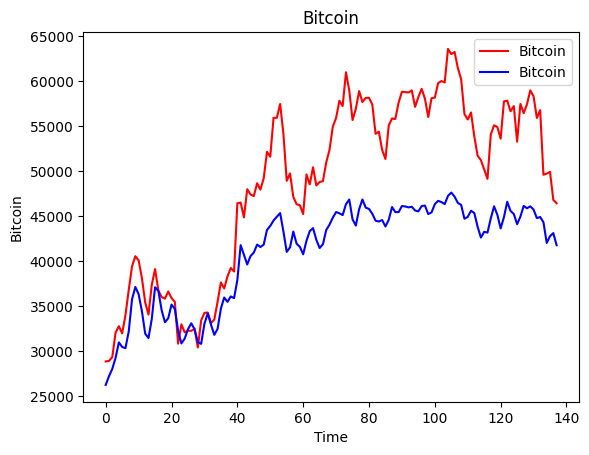

In [15]:
plt.plot(test_data_set[:, 0], color='red', label='Bitcoin')
plt.plot(predicted_data_set[:, 0], color='blue', label='Bitcoin')
plt.title('Bitcoin')
plt.xlabel('Time')
plt.ylabel('Bitcoin')
plt.legend()
plt.show()

In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


mse = mean_squared_error(test_data_set[:, 0], predicted_data_set[:, 0])
rmse = np.sqrt(mse)
mae = mean_absolute_error(test_data_set[:, 0], predicted_data_set[:, 0])
r2 = r2_score(test_data_set[:, 0], predicted_data_set[:, 0])

# Print the performance metrics
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R-squared (R2 Score): {r2}")

Mean Squared Error (MSE): 77996832.26679982
Root Mean Squared Error (RMSE): 8831.581526929354
Mean Absolute Error (MAE): 7647.516997514011
R-squared (R2 Score): 0.186228758561917


In [26]:
def predict_future_stock_prices(model, last_known_data, num_future_steps):
    predictions = []
    current_input = last_known_data.copy()
    for _ in range(num_future_steps):
        pred = model.predict(current_input[np.newaxis, :, :], verbose=0)
        next_step_features = current_input[-1].copy()
        next_step_features[0] = pred[0, 0]
        current_input = np.vstack((current_input[1:], next_step_features))
        predictions.append(pred[0, 0])
    return np.array(predictions)

last_known_data = inputs[-31:]
num_future_steps = 30
future_predictions = predict_future_stock_prices(final_model, last_known_data, num_future_steps)

predicted_full_features = np.zeros((future_predictions.shape[0], 4))
predicted_full_features[:, 0] = future_predictions
future_predictions_inverse = sc.inverse_transform(predicted_full_features)[:, 0]

future_dates = pd.date_range(start=test_data['Date'].iloc[-1] + pd.Timedelta(days=1), periods=num_future_steps)
future_df = pd.DataFrame({'Date': future_dates, 'Predicted Stock Price': future_predictions_inverse})
future_df


,Date,Predicted Stock Price
0,2021-05-19,40275.392369
1,2021-05-20,39926.448423
2,2021-05-21,40576.908775
3,2021-05-22,40975.861903
4,2021-05-23,40635.052568
5,2021-05-24,40087.240936
6,2021-05-25,39808.222168
7,2021-05-26,39817.912259
8,2021-05-27,39879.092325
9,2021-05-28,39829.174067
